## 1. Imports

In [2]:
from pathlib import Path
import json
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

## 2. Project paths


In [3]:
PROJECT_DIR = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")

FULL_CLEAN_DATA_PATH = PROJECT_DIR / "processed_10hz" / "clean_dataset_for_pca.csv"

SPLIT_DIR = PROJECT_DIR / "splits"

TRAIN_SPLIT_PATH = SPLIT_DIR / "train_model_ready_selected_features.csv"
VAL_SPLIT_PATH = SPLIT_DIR / "val_model_ready_selected_features.csv"
TEST_SPLIT_PATH = SPLIT_DIR / "test_model_ready_selected_features.csv"

PCA_OUTPUT_DIR = PROJECT_DIR / "model_ready_with_pca"
PCA_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("PCA input dataset:", FULL_CLEAN_DATA_PATH)
print("Split directory:", SPLIT_DIR)
print("PCA output directory:", PCA_OUTPUT_DIR)

Project directory: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project
PCA input dataset: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/processed_10hz/clean_dataset_for_pca.csv
Split directory: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/splits
PCA output directory: /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_with_pca


## 3. cleaned full dataset loading from eda cleaning

In [4]:
if not FULL_CLEAN_DATA_PATH.exists():
    raise FileNotFoundError(f"PCA input dataset not found: {FULL_CLEAN_DATA_PATH}")

df = pd.read_csv(FULL_CLEAN_DATA_PATH, low_memory=False)

print("PCA input dataset loaded.")
print("Shape:", df.shape)
print("Unique flights:", df["log_id"].nunique())

print("\nLabel distribution:")
print(df["dataset_label"].value_counts())

display(df.head())

PCA input dataset loaded.
Shape: (971822, 378)
Unique flights: 168

Label distribution:
dataset_label
normal      690380
abnormal    281442
Name: count, dtype: int64


,log_id,dataset_label,time_td,actuator_outputs__noutputs,actuator_outputs__output[0],actuator_outputs__output[1],actuator_outputs__output[2],actuator_outputs__output[3],actuator_outputs__output[4],actuator_outputs__output[5],...,vehicle_status__usb_connected,vehicle_status__open_drone_id_system_present,vehicle_status__open_drone_id_system_healthy,vehicle_status__parachute_system_present,vehicle_status__parachute_system_healthy,vehicle_status__avoidance_system_required,vehicle_status__avoidance_system_valid,vehicle_status__rc_calibration_in_progress,vehicle_status__calibration_enabled,vehicle_status__pre_flight_checks_pass
0,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.100000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.200000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,0 days 00:00:00.400000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Loading same train/validation/test flight IDs

In [5]:
for path in [TRAIN_SPLIT_PATH, VAL_SPLIT_PATH, TEST_SPLIT_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Split file not found: {path}")

train_split_df = pd.read_csv(TRAIN_SPLIT_PATH, low_memory=False)
val_split_df = pd.read_csv(VAL_SPLIT_PATH, low_memory=False)
test_split_df = pd.read_csv(TEST_SPLIT_PATH, low_memory=False)

for split_name, split_data in {
    "train_split_df": train_split_df,
    "val_split_df": val_split_df,
    "test_split_df": test_split_df
}.items():
    if "log_id" not in split_data.columns:
        raise ValueError(f"log_id missing from {split_name}")

train_ids = set(train_split_df["log_id"].astype(str).unique())
val_ids = set(val_split_df["log_id"].astype(str).unique())
test_ids = set(test_split_df["log_id"].astype(str).unique())

print("Train flights:", len(train_ids))
print("Validation flights:", len(val_ids))
print("Test flights:", len(test_ids))

Train flights: 117
Validation flights: 25
Test flights: 26


## 5. Flight-level leakage check

to check whether the same flight log appears in more than one dataset split.

In [6]:
print("Train-Val overlap:", len(train_ids & val_ids))
print("Train-Test overlap:", len(train_ids & test_ids))
print("Val-Test overlap:", len(val_ids & test_ids))

assert len(train_ids & val_ids) == 0
assert len(train_ids & test_ids) == 0
assert len(val_ids & test_ids) == 0

print("No flight-level leakage found.")

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0
No flight-level leakage found.


## 6. Flight-level leakage check

checks whether filtering by the split IDs accidentally removed any rows or flights.

In [7]:
all_split_ids = train_ids | val_ids | test_ids

before_rows = df.shape[0]
before_flights = df["log_id"].nunique()

df = df[df["log_id"].isin(all_split_ids)].copy()

after_rows = df.shape[0]
after_flights = df["log_id"].nunique()

print("Rows before filtering to split IDs:", before_rows)
print("Rows after filtering to split IDs:", after_rows)

print("Flights before:", before_flights)
print("Flights after:", after_flights)

print("\nLabel distribution after filtering:")
print(df["dataset_label"].value_counts())

Rows before filtering to split IDs: 971822
Rows after filtering to split IDs: 971822
Flights before: 168
Flights after: 168

Label distribution after filtering:
dataset_label
normal      690380
abnormal    281442
Name: count, dtype: int64


## 8. train/validation/test datasets from full clean data

In [8]:
train_df = df[df["log_id"].isin(train_ids)].copy()
val_df = df[df["log_id"].isin(val_ids)].copy()
test_df = df[df["log_id"].isin(test_ids)].copy()

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

print("\nTrain labels:")
print(train_df["dataset_label"].value_counts())

print("\nValidation labels:")
print(val_df["dataset_label"].value_counts())

print("\nTest labels:")
print(test_df["dataset_label"].value_counts())

Train shape: (694549, 378)
Validation shape: (138749, 378)
Test shape: (138524, 378)

Train labels:
dataset_label
normal      497250
abnormal    197299
Name: count, dtype: int64

Validation labels:
dataset_label
normal      92724
abnormal    46025
Name: count, dtype: int64

Test labels:
dataset_label
normal      100406
abnormal     38118
Name: count, dtype: int64


## 9. target and leakage columns

In [9]:
target_col = "target_energy_next_60s_wh"

non_feature_cols = [
    "log_id",
    "dataset_label",
    "time_td"
]

leakage_cols = [
    "target_energy_next_60s_wh",
    "future_cumulative_energy_wh",
    "future_remaining_60s",
    "target_remaining_drop_60s"
]

# These columns are structurally missing in many flights,
# so they are removed instead of being median-imputed , code done in pre processing.
structurally_missing_cols = [
    "battery_status__voltage_cell_v[0]",
    "battery_status__voltage_cell_v[1]",
    "battery_status__voltage_cell_v[2]",
    "battery_status__voltage_cell_v[3]"
]

cols_to_exclude = non_feature_cols + leakage_cols + structurally_missing_cols

existing_excluded_cols = [
    col for col in cols_to_exclude
    if col in df.columns
]

print("Excluded columns:")
for col in existing_excluded_cols:
    print("-", col)

Excluded columns:
- log_id
- dataset_label
- time_td
- target_energy_next_60s_wh
- future_cumulative_energy_wh
- battery_status__voltage_cell_v[0]
- battery_status__voltage_cell_v[1]
- battery_status__voltage_cell_v[2]
- battery_status__voltage_cell_v[3]


## 10. numeric candidate features selection

removes target/leakage/non-feature columns

In [10]:
numeric_cols = [
    col for col in df.columns
    if pd.api.types.is_numeric_dtype(df[col])
]

feature_cols = [
    col for col in numeric_cols
    if col not in cols_to_exclude
]

print("Initial numeric candidate feature count:", len(feature_cols))
print(feature_cols)

Initial numeric candidate feature count: 363
['actuator_outputs__noutputs', 'actuator_outputs__output[0]', 'actuator_outputs__output[1]', 'actuator_outputs__output[2]', 'actuator_outputs__output[3]', 'actuator_outputs__output[4]', 'actuator_outputs__output[5]', 'actuator_outputs__output[6]', 'actuator_outputs__output[7]', 'actuator_outputs__output[8]', 'actuator_outputs__output[9]', 'actuator_outputs__output[10]', 'actuator_outputs__output[11]', 'actuator_outputs__output[12]', 'actuator_outputs__output[13]', 'actuator_outputs__output[14]', 'actuator_outputs__output[15]', 'actuator_outputs_1__noutputs', 'actuator_outputs_1__output[0]', 'actuator_outputs_1__output[1]', 'actuator_outputs_1__output[2]', 'actuator_outputs_1__output[3]', 'actuator_outputs_1__output[4]', 'actuator_outputs_1__output[5]', 'actuator_outputs_1__output[6]', 'actuator_outputs_1__output[7]', 'actuator_outputs_1__output[8]', 'actuator_outputs_1__output[9]', 'actuator_outputs_1__output[10]', 'actuator_outputs_1__outpu

## 11. Removing timestamp related colomns

because they mainly represented sensor logging time rather than useful flight or battery behaviour.

In [11]:
timestamp_like_cols = [
    "actuator_outputs_1__time_td",
    "sensor_combined__accelerometer_timestamp_relative",
    "sensor_combined__magnetometer_timestamp_relative",
    "sensor_combined__baro_timestamp_relative",
    "vehicle_attitude__time_td",
    "vehicle_gps_position__time_utc_usec",
    "vehicle_gps_position__timestamp_time_relative",
    "vehicle_gps_position__time_td",
    "vehicle_local_position__ref_timestamp",
    "vehicle_local_position__surface_bottom_timestamp",
    "vehicle_local_position__time_td",
    "vehicle_air_data__time_td",
    "vehicle_angular_velocity__timestamp_sample",
    "vehicle_status__nav_state_timestamp",
    "vehicle_acceleration__timestamp_sample",
    "vehicle_air_data__timestamp_sample",
    "vehicle_attitude__timestamp_sample",
    "vehicle_local_position__timestamp_sample",
    "vehicle_status__failsafe_timestamp",
    "vehicle_status__armed_time",
    "vehicle_status__takeoff_time",
    "airspeed__time_td",
    "actuator_motors__timestamp_sample",
    "actuator_motors__time_td",
    "vehicle_gps_position__timestamp_sample"
]

timestamp_like_cols = [
    col for col in timestamp_like_cols
    if col in feature_cols
]

print("Timestamp-like columns to remove:", len(timestamp_like_cols))
print(timestamp_like_cols)

feature_cols = [
    col for col in feature_cols
    if col not in timestamp_like_cols
]

print("Feature count after timestamp-like removal:", len(feature_cols))

Timestamp-like columns to remove: 25
['actuator_outputs_1__time_td', 'sensor_combined__accelerometer_timestamp_relative', 'sensor_combined__magnetometer_timestamp_relative', 'sensor_combined__baro_timestamp_relative', 'vehicle_attitude__time_td', 'vehicle_gps_position__time_utc_usec', 'vehicle_gps_position__timestamp_time_relative', 'vehicle_gps_position__time_td', 'vehicle_local_position__ref_timestamp', 'vehicle_local_position__surface_bottom_timestamp', 'vehicle_local_position__time_td', 'vehicle_air_data__time_td', 'vehicle_angular_velocity__timestamp_sample', 'vehicle_status__nav_state_timestamp', 'vehicle_acceleration__timestamp_sample', 'vehicle_air_data__timestamp_sample', 'vehicle_attitude__timestamp_sample', 'vehicle_local_position__timestamp_sample', 'vehicle_status__failsafe_timestamp', 'vehicle_status__armed_time', 'vehicle_status__takeoff_time', 'airspeed__time_td', 'actuator_motors__timestamp_sample', 'actuator_motors__time_td', 'vehicle_gps_position__timestamp_sample']


## 12. duplicate feature removal

energy_increment_wh = power_w × time interval / 3600

In [12]:
if "power_w" in feature_cols and "energy_increment_wh" in feature_cols:
    feature_cols.remove("energy_increment_wh")
    print("Removed energy_increment_wh because power_w already captures the same energy-use signal at 10 Hz.")

print("Feature count after duplicate-style removal:", len(feature_cols))
print(feature_cols)

Removed energy_increment_wh because power_w already captures the same energy-use signal at 10 Hz.
Feature count after duplicate-style removal: 337
['actuator_outputs__noutputs', 'actuator_outputs__output[0]', 'actuator_outputs__output[1]', 'actuator_outputs__output[2]', 'actuator_outputs__output[3]', 'actuator_outputs__output[4]', 'actuator_outputs__output[5]', 'actuator_outputs__output[6]', 'actuator_outputs__output[7]', 'actuator_outputs__output[8]', 'actuator_outputs__output[9]', 'actuator_outputs__output[10]', 'actuator_outputs__output[11]', 'actuator_outputs__output[12]', 'actuator_outputs__output[13]', 'actuator_outputs__output[14]', 'actuator_outputs__output[15]', 'actuator_outputs_1__noutputs', 'actuator_outputs_1__output[0]', 'actuator_outputs_1__output[1]', 'actuator_outputs_1__output[2]', 'actuator_outputs_1__output[3]', 'actuator_outputs_1__output[4]', 'actuator_outputs_1__output[5]', 'actuator_outputs_1__output[6]', 'actuator_outputs_1__output[7]', 'actuator_outputs_1__out

## 13. Create X and y

In [13]:
X_train = train_df[feature_cols].copy()
X_val = val_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()

y_train = train_df[target_col].copy()
y_val = val_df[target_col].copy()
y_test = test_df[target_col].copy()


X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_val = X_val.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\ny_train:", y_train.shape) # series 1d, 1 colomn
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

X_train: (694549, 337)
X_val: (138749, 337)
X_test: (138524, 337)

y_train: (694549,)
y_val: (138749,)
y_test: (138524,)


## 14. Removing rows with missing target if any

In [14]:
print("Missing target values:")
print("Train:", y_train.isna().sum())
print("Validation:", y_val.isna().sum())
print("Test:", y_test.isna().sum())

# Usually this should be zero because target cleaning was already done
train_valid_target = ~y_train.isna()
val_valid_target = ~y_val.isna()
test_valid_target = ~y_test.isna()

X_train = X_train.loc[train_valid_target].copy()
y_train = y_train.loc[train_valid_target].copy()
train_df = train_df.loc[train_valid_target].copy()

X_val = X_val.loc[val_valid_target].copy()
y_val = y_val.loc[val_valid_target].copy()
val_df = val_df.loc[val_valid_target].copy()

X_test = X_test.loc[test_valid_target].copy()
y_test = y_test.loc[test_valid_target].copy()
test_df = test_df.loc[test_valid_target].copy()

print("After target check:")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

Missing target values:
Train: 0
Validation: 0
Test: 0
After target check:
X_train: (694549, 337)
X_val: (138749, 337)
X_test: (138524, 337)


## 15. Missing-value report before filtering

In [15]:
missing_report_before = pd.DataFrame({
    "feature": feature_cols,
    "train_missing_%": X_train.isna().mean().values * 100,
    "val_missing_%": X_val.isna().mean().values * 100,
    "test_missing_%": X_test.isna().mean().values * 100
}).sort_values("train_missing_%", ascending=False)

display(missing_report_before)

missing_report_before.to_csv(
    PCA_OUTPUT_DIR / "missing_report_before_pca_filtering.csv",
    index=False
)

,feature,train_missing_%,val_missing_%,test_missing_%
336,vehicle_status__pre_flight_checks_pass,100.0,100.0,100.0
113,vehicle_local_position__v_xy_valid,100.0,100.0,100.0
144,vehicle_status__time_td,100.0,100.0,100.0
302,vehicle_gps_position__altitude_msl_m,100.0,100.0,100.0
301,vehicle_gps_position__longitude_deg,100.0,100.0,100.0
...,...,...,...,...
36,battery_status__current_a,0.0,0.0,0.0
37,battery_status__current_filtered_a,0.0,0.0,0.0
38,battery_status__discharged_mah,0.0,0.0,0.0
39,battery_status__remaining,0.0,0.0,0.0


## 16. Remove 100% missing, >80% missing, and constant columns using train only

In [16]:
MISSING_THRESHOLD = 80

train_missing_percent = X_train.isna().mean() * 100
train_unique_counts = X_train.nunique(dropna=True)

cols_100_missing = train_missing_percent[train_missing_percent == 100].index.tolist()
cols_high_missing = train_missing_percent[train_missing_percent > MISSING_THRESHOLD].index.tolist()
cols_constant = train_unique_counts[train_unique_counts <= 1].index.tolist()

cols_to_drop = sorted(list(set(cols_100_missing + cols_high_missing + cols_constant)))

print("100% missing columns:", len(cols_100_missing))
print(cols_100_missing)

print("\nMore than 80% missing columns:", len(cols_high_missing))
print(cols_high_missing)

print("\nConstant columns:", len(cols_constant))
print(cols_constant)

print("\nTotal columns to drop:", len(cols_to_drop))

100% missing columns: 225
['actuator_outputs_1__noutputs', 'actuator_outputs_1__output[0]', 'actuator_outputs_1__output[1]', 'actuator_outputs_1__output[2]', 'actuator_outputs_1__output[3]', 'actuator_outputs_1__output[4]', 'actuator_outputs_1__output[5]', 'actuator_outputs_1__output[6]', 'actuator_outputs_1__output[7]', 'actuator_outputs_1__output[8]', 'actuator_outputs_1__output[9]', 'actuator_outputs_1__output[10]', 'actuator_outputs_1__output[11]', 'actuator_outputs_1__output[12]', 'actuator_outputs_1__output[13]', 'actuator_outputs_1__output[14]', 'actuator_outputs_1__output[15]', 'sensor_combined__magnetometer_ga[0]', 'sensor_combined__magnetometer_ga[1]', 'sensor_combined__magnetometer_ga[2]', 'sensor_combined__baro_alt_meter', 'sensor_combined__baro_temp_celcius', 'vehicle_attitude__rollspeed', 'vehicle_attitude__pitchspeed', 'vehicle_attitude__yawspeed', 'vehicle_attitude__q[0]', 'vehicle_attitude__q[1]', 'vehicle_attitude__q[2]', 'vehicle_attitude__q[3]', 'vehicle_gps_positio

## 17. feature filtering

In [17]:
feature_cols_filtered = [col for col in feature_cols if col not in cols_to_drop]

X_train = X_train[feature_cols_filtered].copy()
X_val = X_val[feature_cols_filtered].copy()
X_test = X_test[feature_cols_filtered].copy()

feature_cols = feature_cols_filtered

print("Final candidate feature count before imputation/scaling/PCA:", len(feature_cols))
print(feature_cols)

Final candidate feature count before imputation/scaling/PCA: 13
['battery_status__voltage_v', 'battery_status__voltage_filtered_v', 'battery_status__current_a', 'battery_status__current_filtered_a', 'battery_status__discharged_mah', 'battery_status__remaining', 'battery_status__scale', 'battery_status__cell_count', 'battery_status__warning', 'time_s', 'power_w', 'cumulative_energy_wh', 'battery_status__system_source']


## 18. Missing-value report after filtering

In [18]:
missing_report_after = pd.DataFrame({
    "feature": feature_cols,
    "train_missing_%": X_train.isna().mean().values * 100,
    "val_missing_%": X_val.isna().mean().values * 100,
    "test_missing_%": X_test.isna().mean().values * 100
}).sort_values("train_missing_%", ascending=False)

display(missing_report_after)

missing_report_after.to_csv(
    PCA_OUTPUT_DIR / "missing_report_after_pca_filtering.csv",
    index=False
)

,feature,train_missing_%,val_missing_%,test_missing_%
12,battery_status__system_source,17.373144,8.877902,13.349311
0,battery_status__voltage_v,0.000000,0.000000,0.000000
1,battery_status__voltage_filtered_v,0.000000,0.000000,0.000000
2,battery_status__current_a,0.000000,0.000000,0.000000
3,battery_status__current_filtered_a,0.000000,0.000000,0.000000
4,battery_status__discharged_mah,0.000000,0.000000,0.000000
5,battery_status__remaining,0.000000,0.000000,0.000000
6,battery_status__scale,0.000000,0.000000,0.000000
7,battery_status__cell_count,0.000000,0.000000,0.000000
8,battery_status__warning,0.000000,0.000000,0.000000


## 20. Standardisation

Mean ≈ 0
Standard deviation ≈ 1

In [19]:
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=feature_cols,
    index=X_train.index
)

X_val_scaled = pd.DataFrame(
    scaler.transform(X_val),
    columns=feature_cols,
    index=X_val.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=feature_cols,
    index=X_test.index
)

print("Scaled train shape:", X_train_scaled.shape)
print("Scaled validation shape:", X_val_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)

Scaled train shape: (694549, 13)
Scaled validation shape: (138749, 13)
Scaled test shape: (138524, 13)


## 21. Scaling

In [20]:
scale_summary = pd.DataFrame({
    "feature": feature_cols,
    "scaled_train_mean": X_train_scaled.mean().values,
    "scaled_train_std": X_train_scaled.std().values
})

display(scale_summary)

scale_summary.to_csv(
    PCA_OUTPUT_DIR / "scaling_check_before_pca.csv",
    index=False
)

,feature,scaled_train_mean,scaled_train_std
0,battery_status__voltage_v,-2.514192e-16,1.000001
1,battery_status__voltage_filtered_v,4.818869e-16,1.000001
2,battery_status__current_a,1.990402e-16,1.000001
3,battery_status__current_filtered_a,9.428222e-17,1.000001
4,battery_status__discharged_mah,1.466612e-16,1.000001
5,battery_status__remaining,1.335665e-16,1.000001
6,battery_status__scale,1.539943e-15,1.000001
7,battery_status__cell_count,0.000000e+00,1.000001
8,battery_status__warning,-1.571370e-17,1.000001
9,time_s,8.380641e-17,1.000001


## 22. fit PCA on training data

In [22]:
# Diagnose
print("NaNs in X_train_scaled:", X_train_scaled.isna().sum().sum())
print("\nPer-column NaN count (only those with NaNs):")
nan_cols = X_train_scaled.isna().sum()
print(nan_cols[nan_cols > 0])

NaNs in X_train_scaled: 120665

Per-column NaN count (only those with NaNs):
battery_status__system_source    120665
dtype: int64


In [23]:
# Drop columns that still have NaNs (train-only decision)
nan_cols_to_drop = X_train_scaled.columns[X_train_scaled.isna().any()].tolist()
print("Dropping columns with NaNs:", nan_cols_to_drop)

X_train_scaled = X_train_scaled.drop(columns=nan_cols_to_drop)
X_val_scaled   = X_val_scaled.drop(columns=nan_cols_to_drop)
X_test_scaled  = X_test_scaled.drop(columns=nan_cols_to_drop)

feature_cols = X_train_scaled.columns.tolist()

print("X_train_scaled shape after drop:", X_train_scaled.shape)
print("Remaining NaNs:", X_train_scaled.isna().sum().sum())

Dropping columns with NaNs: ['battery_status__system_source']
X_train_scaled shape after drop: (694549, 12)
Remaining NaNs: 0


In [25]:
pca_full = PCA(random_state=42)

X_train_pca_full = pca_full.fit_transform(X_train_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

pca_variance_df = pd.DataFrame({
    "component_number": range(1, len(explained_variance) + 1),
    "component": [f"PC{i+1}" for i in range(len(explained_variance))],
    "explained_variance_ratio": explained_variance,
    "cumulative_variance": cumulative_variance
})

display(pca_variance_df)

pca_variance_df.to_csv(
    PCA_OUTPUT_DIR / "pca_explained_variance_full.csv",
    index=False
)

,component_number,component,explained_variance_ratio,cumulative_variance
0,1,PC1,0.431206,0.431206
1,2,PC2,0.222319,0.653525
2,3,PC3,0.142763,0.796288
3,4,PC4,0.081918,0.878206
4,5,PC5,0.063468,0.941674
5,6,PC6,0.036053,0.977727
6,7,PC7,0.011749,0.989476
7,8,PC8,0.004873,0.994349
8,9,PC9,0.002175,0.996524
9,10,PC10,0.001701,0.998225


## 23. Scree plot

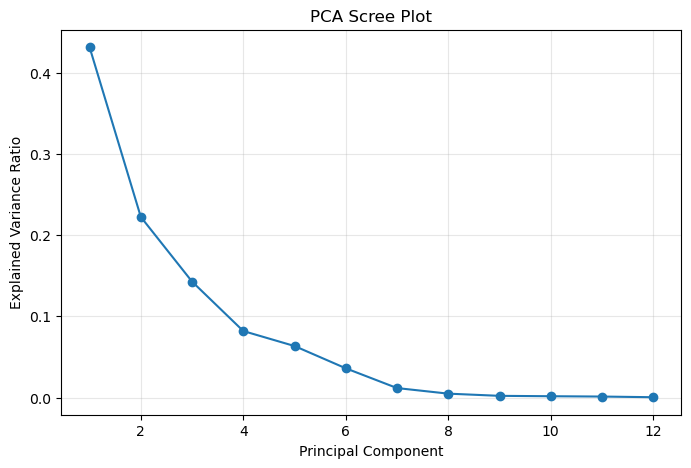

In [26]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker="o"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Scree Plot")
plt.grid(True, alpha=0.3)
plt.show()

## 24. Cumulative explained variance plot

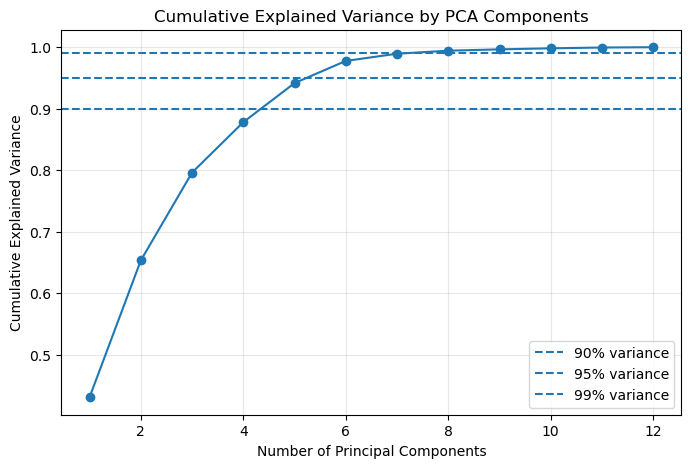

In [27]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(y=0.90, linestyle="--", label="90% variance")
plt.axhline(y=0.95, linestyle="--", label="95% variance")
plt.axhline(y=0.99, linestyle="--", label="99% variance")

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance by PCA Components")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 25. PCA component count selection

In [28]:
variance_threshold = 0.95

n_components = np.argmax(cumulative_variance >= variance_threshold) + 1

print(f"Selected variance threshold: {variance_threshold * 100:.0f}%")
print("Original candidate feature count:", len(feature_cols))
print("Selected PCA component count:", n_components)
print("Variance retained:", cumulative_variance[n_components - 1])

print("\nComponent counts for common thresholds:")
for threshold in [0.90, 0.95, 0.99]:
    n = np.argmax(cumulative_variance >= threshold) + 1
    print(f"{threshold*100:.0f}% variance: {n} components")

Selected variance threshold: 95%
Original candidate feature count: 12
Selected PCA component count: 6
Variance retained: 0.9777274055149063

Component counts for common thresholds:
90% variance: 5 components
95% variance: 6 components
99% variance: 8 components


## 26. Fitting final PCA using selected components

In [29]:
pca = PCA(n_components=n_components, random_state=42)

X_train_pca = pca.fit_transform(X_train_scaled)
X_val_pca = pca.transform(X_val_scaled)
X_test_pca = pca.transform(X_test_scaled)

pca_feature_cols = [f"PC{i+1}" for i in range(n_components)]

print("X_train_pca:", X_train_pca.shape)
print("X_val_pca:", X_val_pca.shape)
print("X_test_pca:", X_test_pca.shape)

print("PCA feature columns:")
print(pca_feature_cols)

X_train_pca: (694549, 6)
X_val_pca: (138749, 6)
X_test_pca: (138524, 6)
PCA feature columns:
['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6']


## 27. PCA loadings

Which original features contribute most to each PCA component

In [30]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=feature_cols,
    columns=pca_feature_cols
)

display(loadings)

loadings.to_csv(PCA_OUTPUT_DIR / "pca_loadings.csv")

,PC1,PC2,PC3,PC4,PC5,PC6
battery_status__voltage_v,0.316362,0.381671,-0.173187,0.057112,-0.156634,0.119665
battery_status__voltage_filtered_v,0.318775,0.381493,-0.170638,0.056292,-0.155785,0.121698
battery_status__current_a,0.297506,-0.209111,0.475415,-0.005243,-0.024970,0.220614
battery_status__current_filtered_a,0.299885,-0.210700,0.470833,-0.004596,-0.024388,0.202791
battery_status__discharged_mah,0.364454,-0.199226,-0.011481,-0.073893,0.277852,-0.471689
battery_status__remaining,-0.100524,0.487321,0.310681,0.000101,0.415204,-0.022227
battery_status__scale,0.156365,-0.453715,-0.347487,-0.027897,-0.353470,0.010183
battery_status__cell_count,0.349846,0.306783,-0.188623,0.049974,-0.225575,0.062756
battery_status__warning,0.025157,-0.104663,-0.018710,0.986109,0.115968,-0.039520
time_s,0.169920,-0.180445,-0.410513,-0.084567,0.651272,0.578635


## 28. Top contributing features per component

In [31]:
top_loading_rows = []

for pc in pca_feature_cols:
    top_features = (
        loadings[pc]
        .abs()
        .sort_values(ascending=False)
        .head(5)
    )

    print(f"\nTop contributing features for {pc}:")
    display(top_features)

    for feature, abs_value in top_features.items():
        top_loading_rows.append({
            "principal_component": pc,
            "feature": feature,
            "absolute_loading": abs_value,
            "signed_loading": loadings.loc[feature, pc]
        })

top_loadings_df = pd.DataFrame(top_loading_rows)

top_loadings_df.to_csv(
    PCA_OUTPUT_DIR / "pca_top_feature_contributors.csv",
    index=False
)


Top contributing features for PC1:


power_w                               0.394773
cumulative_energy_wh                  0.380436
battery_status__discharged_mah        0.364454
battery_status__cell_count            0.349846
battery_status__voltage_filtered_v    0.318775
Name: PC1, dtype: float64


Top contributing features for PC2:


battery_status__remaining             0.487321
battery_status__scale                 0.453715
battery_status__voltage_v             0.381671
battery_status__voltage_filtered_v    0.381493
battery_status__cell_count            0.306783
Name: PC2, dtype: float64


Top contributing features for PC3:


...

battery_status__warning           0.986109
time_s                            0.084567
battery_status__discharged_mah    0.073893
cumulative_energy_wh              0.072030
battery_status__voltage_v         0.057112
Name: PC4, dtype: float64


Top contributing features for PC5:


time_s                            0.651272
battery_status__remaining         0.415204
battery_status__scale             0.353470
cumulative_energy_wh              0.283045
battery_status__discharged_mah    0.277852
Name: PC5, dtype: float64


Top contributing features for PC6:


time_s                                0.578635
cumulative_energy_wh                  0.546916
battery_status__discharged_mah        0.471689
battery_status__current_a             0.220614
battery_status__current_filtered_a    0.202791
Name: PC6, dtype: float64

## 28. Creating PCA model-ready datasets

In [32]:
X_train_pca_df = pd.DataFrame(X_train_pca, columns=pca_feature_cols)
X_val_pca_df = pd.DataFrame(X_val_pca, columns=pca_feature_cols)
X_test_pca_df = pd.DataFrame(X_test_pca, columns=pca_feature_cols)

train_pca = pd.concat([
    train_df[["log_id", "dataset_label"]].reset_index(drop=True),
    X_train_pca_df.reset_index(drop=True),
    y_train.reset_index(drop=True).rename(target_col)
], axis=1)

val_pca = pd.concat([
    val_df[["log_id", "dataset_label"]].reset_index(drop=True),
    X_val_pca_df.reset_index(drop=True),
    y_val.reset_index(drop=True).rename(target_col)
], axis=1)

test_pca = pd.concat([
    test_df[["log_id", "dataset_label"]].reset_index(drop=True),
    X_test_pca_df.reset_index(drop=True),
    y_test.reset_index(drop=True).rename(target_col)
], axis=1)

print("PCA train:", train_pca.shape)
print("PCA validation:", val_pca.shape)
print("PCA test:", test_pca.shape)

display(train_pca.head())

PCA train: (694549, 9)
PCA validation: (138749, 9)
PCA test: (138524, 9)


,log_id,dataset_label,PC1,PC2,PC3,PC4,PC5,PC6,target_energy_next_60s_wh
0,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,-1.868896,0.742786,0.064868,0.051665,-0.286316,-0.734328,0.001262
1,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,-1.868849,0.742736,0.064754,0.051642,-0.286137,-0.734168,0.001262
2,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,-1.868802,0.742687,0.064641,0.051618,-0.285957,-0.734009,0.001262
3,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,-1.868755,0.742637,0.064528,0.051595,-0.285778,-0.733849,0.001262
4,00209ad8-f7c4-4d6f-839c-af19d8203e9b,normal,-1.795201,0.535832,-0.045986,0.045138,-0.447927,-0.714949,0.001109


## 29. Final quality check

In [33]:
def check_dataset(name, data):
    print(f"\n{name}")
    print("-" * 40)
    print("Shape:", data.shape)
    print("Missing values:", data.isna().sum().sum())
    print("Unique flights:", data["log_id"].nunique())
    print("Target missing:", data[target_col].isna().sum())
    print("Label distribution:")
    print(data["dataset_label"].value_counts())

check_dataset("Train PCA", train_pca)
check_dataset("Validation PCA", val_pca)
check_dataset("Test PCA", test_pca)


Train PCA
----------------------------------------
Shape: (694549, 9)
Missing values: 0
Unique flights: 117
Target missing: 0
Label distribution:
dataset_label
normal      497250
abnormal    197299
Name: count, dtype: int64

Validation PCA
----------------------------------------
Shape: (138749, 9)
Missing values: 0
Unique flights: 25
Target missing: 0
Label distribution:
dataset_label
normal      92724
abnormal    46025
Name: count, dtype: int64

Test PCA
----------------------------------------
Shape: (138524, 9)
Missing values: 0
Unique flights: 26
Target missing: 0
Label distribution:
dataset_label
normal      100406
abnormal     38118
Name: count, dtype: int64


## 30. PCA datasets saving

In [34]:
train_pca.to_csv(PCA_OUTPUT_DIR / "train_pca_95.csv", index=False)
val_pca.to_csv(PCA_OUTPUT_DIR / "val_pca_95.csv", index=False)
test_pca.to_csv(PCA_OUTPUT_DIR / "test_pca_95.csv", index=False)

print("Saved PCA datasets to:")
print(PCA_OUTPUT_DIR)

Saved PCA datasets to:
/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_ready_with_pca


## 31. Saving  preprocessing objects and feature lists
will be useful for reproducability

In [35]:
joblib.dump(scaler, PCA_OUTPUT_DIR / "standard_scaler_pca.joblib")
joblib.dump(pca, PCA_OUTPUT_DIR / "pca_95_model.joblib")
with open(PCA_OUTPUT_DIR / "candidate_feature_columns_before_pca.json", "w") as f:
    json.dump(feature_cols, f, indent=4)

with open(PCA_OUTPUT_DIR / "pca_feature_columns.json", "w") as f:
    json.dump(pca_feature_cols, f, indent=4)

print("Saved scaler, PCA model, and feature lists.")

Saved scaler, PCA model, and feature lists.
